
### Challenge 4: Quantum Correlation Switch

**Tasks:**
- **Part A – Correlated Outcomes:** Design and execute a two-qubit circuit where measurement results are predominantly `00` and `11`.
- **Part B – Opposite Outcomes:** Modify the circuit so measurement results are predominantly `01` and `10`.
- **Part C – Comparison & Detailed Analysis:** Compare both circuits using side-by-side histograms, and thoroughly explain the physical and statistical principles governing the switch.

In [5]:
# Step 1: Import required modules and initialize simulator
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Initialize simulator backend
simulator = AerSimulator()
print("AerSimulator initialized successfully.")


AerSimulator initialized successfully.


---
## Part A: Correlated Outcomes (Switch Position: Correlated)

### Prediction Before Execution
- **Dominant outcomes:** `00` and `11`.
- **Ideal probabilities:** $P(00) = 50\%$, $P(11) = 50\%$, $P(01) = 0\%$, $P(10) = 0\%$.
- **Expected counts for 100 shots:** Approximately **50 counts for '00'** and **50 counts for '11'**.


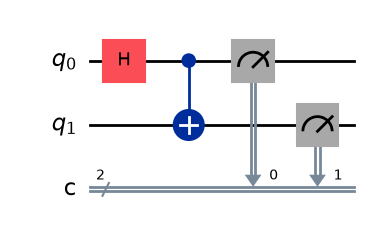

Part A Measurement Results (100 shots): {'00': 58, '11': 42}


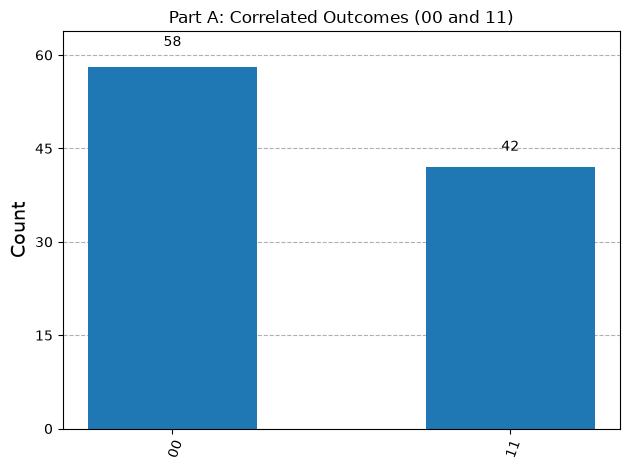

In [6]:
qc_a = QuantumCircuit(2, 2, name="Part A: Correlated (Phi+)")

# Gate 1: H on qubit 0
qc_a.h(0)

# Gate 2: CX with control=0, target=1
qc_a.cx(0, 1)

# Measure both qubits (q0 -> c0, q1 -> c1)
qc_a.measure([0, 1], [0, 1])

# Display circuit diagram
display(qc_a.draw("mpl"))

# Execute for exactly 100 shots
shots = 100
job_a = simulator.run(qc_a, shots=shots)
result_a = job_a.result()
counts_a = result_a.get_counts()

print("Part A Measurement Results (100 shots):", counts_a)
plot_histogram(counts_a, title="Part A: Correlated Outcomes (00 and 11)")


---
## Part B: Opposite Outcomes (Switch Position: Opposite / Anti-Correlated)

###  Prediction Before Execution
- **Dominant outcomes:** `01` and `10`.
- **Ideal probabilities:** $P(01) = 50\%$, $P(10) = 50\%$, $P(00) = 0\%$, $P(11) = 0\%$.
- **Expected counts for 100 shots:** Approximately **50 counts for '01'** and **50 counts for '10'**.


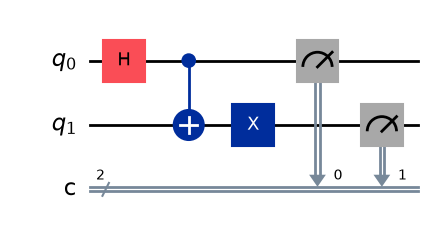

Part B Measurement Results (100 shots): {'10': 49, '01': 51}


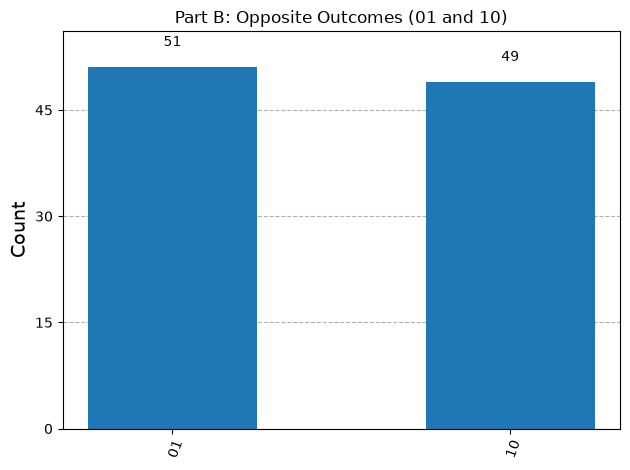

In [7]:
qc_b = QuantumCircuit(2, 2, name="Part B: Opposite (Psi+)")

# Gate 1: H on qubit 0
qc_b.h(0)

# Gate 2: CX with control=0, target=1
qc_b.cx(0, 1)

# Correlation Switch: Add X gate to qubit 1
qc_b.x(1)

# Measure both qubits (q0 -> c0, q1 -> c1)
qc_b.measure([0, 1], [0, 1])

# Display circuit diagram
display(qc_b.draw("mpl"))

# Execute for exactly 100 shots
job_b = simulator.run(qc_b, shots=shots)
result_b = job_b.result()
counts_b = result_b.get_counts()

print("Part B Measurement Results (100 shots):", counts_b)
plot_histogram(counts_b, title="Part B: Opposite Outcomes (01 and 10)")


---
## Part C: Comparative Visualization of Part A and Part B
The side-by-side histogram below visually proves the operation of the quantum correlation switch.


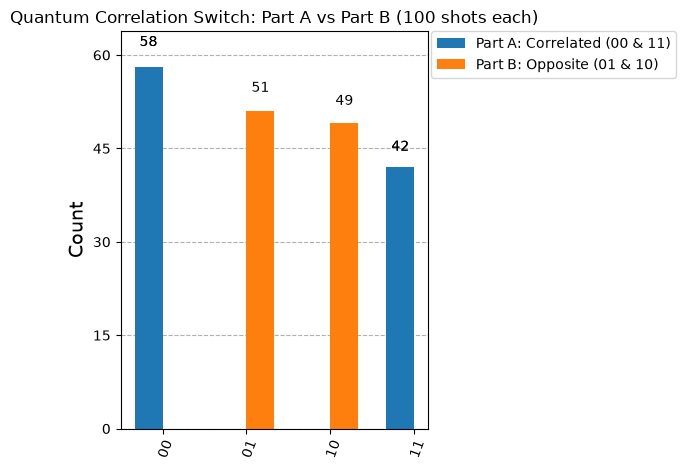

In [8]:
plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated (00 & 11)", "Part B: Opposite (01 & 10)"],
    title="Quantum Correlation Switch: Part A vs Part B (100 shots each)"
)


---
## Comprehensive Analysis of the Quantum Correlation Switch

| Experiment | Gates Applied | Gate Count | Target Entangled State | Dominant Outcomes | Observed Counts (100 shots) | Correlation Behavior |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Part A** | $H(0), CX(0, 1)$ | 2 gates ($\le 4$) | $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ | `00` and `11` | Approximately 50/50 | **Correlated** (Equal values) |
| **Part B** | $H(0), CX(0, 1), X(1)$ | 3 gates ($\le 4$) | $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ | `01` and `10` | Approximately 50/50 | **Opposite** (Inverted values) |


#### 1. Which outcomes are dominant in Part A?
- **Part A:** The dominant (and only observed) outcomes are **`00`** and **`11`**, each occurring in approximately $50\%$ of the shots.

#### 2. Which outcomes are dominant in Part B?
- **Part B:** The dominant (and only observed) outcomes are **`01`** and **`10`**, each occurring in approximately $50\%$ of the shots.

#### 3. What changed between the two circuits?
- Exactly one single-qubit quantum gate was added: a Pauli-$X$ gate on Qubit 1 inserted after the entangling $CX$ gate and before measurement.
- The total gate count changed from 2 gates in Part A to 3 gates in Part B, remaining well within the 4-gate constraint.

#### 4. Why did the measurement relationship change?
- In Part A, Qubit 0 and Qubit 1 are entangled such that their computational values match perfectly: $|00>$ and $|11>$.
- The Pauli-$X$ gate acts as a bit-flip operator: $X|0> = |1>$ and $X|1> = |0>$.
- By applying $X$ to Qubit 1 ($X_1 \otimes I_0$), the state transforms:
  $$|00> \xrightarrow{X_1} |10> \quad, \qquad |11> \xrightarrow{X_1} |01> \quad $$
- Because only one of the two entangled qubits was flipped, the two qubits now always have **opposite values**. The positive correlation in Part A is cleanly inverted into perfect anti-correlation in Part B.